In [1]:
# =============================================
# CELL 1 : INSTALL DEPENDENCIES
# =============================================
!pip install -q scikit-learn xgboost pandas matplotlib seaborn numpy joblib codecarbon
print("✅ Dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.9/396.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 62.8 MB/s eta 0:00:00
✅ Dependencies installed.


In [7]:
# =============================================
# CELL 2 : IMPORTS & CONFIGURATION
# =============================================
import os, time, json, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from google.colab import drive
from codecarbon import OfflineEmissionsTracker

# ML Classifiers
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')

# Mount Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# ─── PATHS ────────────────────────────────────────────────────────────────────
# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

FEATURES_DIR = f"{PROJECT_ROOT}/features"
OUTPUT_DIR   = f"{PROJECT_ROOT}/results"
MODELS_DIR   = f"{PROJECT_ROOT}/ml_models"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# ─── PARAMETERS ───────────────────────────────────────────────────────────────
ARCHITECTURES = ['ResNet50V2', 'DenseNet201', 'EfficientNetB3', 'EfficientNetV2L']
CLASS_NAMES   = ['Non-Nodule', 'Benign', 'Malignant']
RANDOM_SEED   = 42

np.random.seed(RANDOM_SEED)
print("✅ Configuration loaded.")
print(f"   Architectures : {ARCHITECTURES}")
print(f"   Classifiers   : Linear SVM, XGBoost, Random Forest")
print(f"   Total combos  : {len(ARCHITECTURES) * 3}")

✅ Configuration loaded.
   Architectures : ['ResNet50V2', 'DenseNet201', 'EfficientNetB3', 'EfficientNetV2L']
   Classifiers   : Linear SVM, XGBoost, Random Forest
   Total combos  : 12


In [8]:
# =============================================
# CELL 3 : LOAD FEATURES
# =============================================
def load_features(arch_name):
    """
    Load numpy feature arrays for a given CNN architecture.
    Returns: (X_trainval, y_trainval, X_test, y_test, X_train, y_train, X_val, y_val)
    Test set = CORRECTED version (augmented duplicates removed, see manuscript
    Section 3.4.4 and notebook 04_fix_test_set_duplicates.ipynb).
    """
    feat_dir = os.path.join(FEATURES_DIR, arch_name)

    if not os.path.exists(feat_dir):
        print(f"❌ Features not found for {arch_name}: {feat_dir}")
        return None

    X_train = np.load(os.path.join(feat_dir, 'X_train.npy'))
    y_train = np.load(os.path.join(feat_dir, 'y_train.npy'))
    X_val   = np.load(os.path.join(feat_dir, 'X_val.npy'))
    y_val   = np.load(os.path.join(feat_dir, 'y_val.npy'))

    # --- CORRECTED test set (n=2664 instead of 5528) --------------------------
    x_corr = os.path.join(feat_dir, 'X_test_corrected.npy')
    y_corr = os.path.join(feat_dir, 'y_test_corrected.npy')
    if not (os.path.exists(x_corr) and os.path.exists(y_corr)):
        raise FileNotFoundError(
            f"Corrected test files not found for {arch_name}: {x_corr}\n"
            f"-> Run 04_fix_test_set_duplicates.ipynb first."
        )
    X_test = np.load(x_corr)
    y_test = np.load(y_corr)

    # Merge Train + Val for final training (standard practice)
    X_trainval = np.concatenate([X_train, X_val], axis=0)
    y_trainval = np.concatenate([y_train, y_val], axis=0)

    print(f"✅ {arch_name} — Features loaded:")
    print(f"   Train+Val : {X_trainval.shape} | Test : {X_test.shape}")
    return X_trainval, y_trainval, X_test, y_test, X_train, y_train, X_val, y_val

# Validation test
result = load_features(ARCHITECTURES[0])
if result is not None:
    print(f"   Feature dimension : {result[0].shape[1]}")

✅ ResNet50V2 — Features loaded:
   Train+Val : (41796, 2048) | Test : (2664, 2048)
   Feature dimension : 2048


In [9]:
# =============================================
# CELL 4 : CLASSIFIER DEFINITIONS (PATCHED)
# =============================================
# Changes vs original:
#   - LinearSVC: dual=False (n_samples >> n_features → ~10-50x speedup)
#                max_iter reduced (converges fast with dual=False)
#   - CalibratedClassifierCV: n_jobs=-1 (parallel CV folds)
#   - XGBoost: tree_method='hist', n_jobs=-1, removed deprecated
#              use_label_encoder
#   - RandomForest: n_jobs=-1 (parallel trees)
# Expected total time for 12 combos: ~15-30 min instead of ~15-20h.

def get_classifiers():
    """
    Returns a dictionary of classifiers wrapped in StandardScaler pipelines.
    LinearSVC is calibrated with CalibratedClassifierCV to enable predict_proba (for AUC).
    """
    classifiers = {
        'SVM_Linear': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', CalibratedClassifierCV(
                LinearSVC(
                    C=1.0,
                    dual=False,              # n_samples (41k) >> n_features (2048)
                    max_iter=2000,
                    random_state=RANDOM_SEED,
                ),
                cv=3, method='sigmoid',
                n_jobs=-1,                   # parallelize the 3 CV folds
            ))
        ]),

        'XGBoost': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', XGBClassifier(
                n_estimators=300, max_depth=6, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                tree_method='hist',          # 2-3x faster, near-identical accuracy
                n_jobs=-1,
                eval_metric='mlogloss',
                random_state=RANDOM_SEED,
                # use_label_encoder removed (deprecated in XGBoost >= 2.0)
            ))
        ]),

        'RandomForest': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(
                n_estimators=300, max_depth=None,
                min_samples_split=2, min_samples_leaf=1,
                n_jobs=-1,                   # parallelize tree building
                random_state=RANDOM_SEED,
            ))
        ]),
    }
    return classifiers

print("✅ Classifiers defined (patched for speed).")
print("   - SVM_Linear   : dual=False, parallel CV")
print("   - XGBoost      : tree_method='hist', n_jobs=-1")
print("   - RandomForest : n_jobs=-1")

✅ Classifiers defined (patched for speed).
   - SVM_Linear   : dual=False, parallel CV
   - XGBoost      : tree_method='hist', n_jobs=-1
   - RandomForest : n_jobs=-1


In [10]:
# =============================================
# CELL 5 : METRICS COMPUTATION FUNCTION
# =============================================
def compute_metrics(y_true, y_pred, y_proba, class_names):
    """
    Compute all evaluation metrics for a multi-class classifier.
    Returns a dictionary of metrics.
    """
    n_classes = len(class_names)

    # Global metrics
    acc         = accuracy_score(y_true, y_pred)
    prec_macro  = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec_macro   = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1_macro    = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    # Log Loss
    try:
        ll = log_loss(y_true, y_proba)
    except Exception:
        ll = 0.0

    # AUC (One-vs-Rest, macro)
    try:
        auc = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
    except Exception:
        auc = 0.0

    # Specificity (macro) = mean(TN / (TN + FP)) per class
    cm = confusion_matrix(y_true, y_pred)
    specificities = []
    for i in range(n_classes):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - TP - FP - FN
        specificities.append(TN / (TN + FP) if (TN + FP) > 0 else 0)
    specificity_macro = np.mean(specificities)

    # Per-class metrics
    per_class = {}
    for i, cls in enumerate(class_names):
        per_class[cls] = {
            'precision'  : float(precision_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)),
            'recall'     : float(recall_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)),
            'f1'         : float(f1_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)),
            'specificity': float(specificities[i])
        }

    return {
        'accuracy'          : acc,
        'precision_macro'   : prec_macro,
        'recall_macro'      : rec_macro,
        'f1_macro'          : f1_macro,
        'f1_weighted'       : f1_weighted,
        'log_loss'          : ll,
        'auc'               : auc,
        'specificity_macro' : specificity_macro,
        'confusion_matrix'  : cm,
        'per_class'         : per_class
    }

print("✅ compute_metrics() function defined.")
print("   Metrics: Accuracy, Precision, Recall, F1 (Macro/Weighted), Log Loss, AUC, Specificity")

✅ compute_metrics() function defined.
   Metrics: Accuracy, Precision, Recall, F1 (Macro/Weighted), Log Loss, AUC, Specificity



🏗️  FEATURES : CBAM + ResNet50V2
✅ ResNet50V2 — Features loaded:
   Train+Val : (41796, 2048) | Test : (2664, 2048)

   🔹 Classifier : SVM_Linear
      ⏳ Training on 41796 samples...
      Accuracy    : 89.45%
      F1 Macro    : 70.29%
      AUC (OvR)   : 0.9365
      Log Loss    : 0.3118
      Specificity : 90.75%
      ⏱️  Duration : 5625.6s (93.76 min)
      🌱 CO2eq    : 16.4325 g


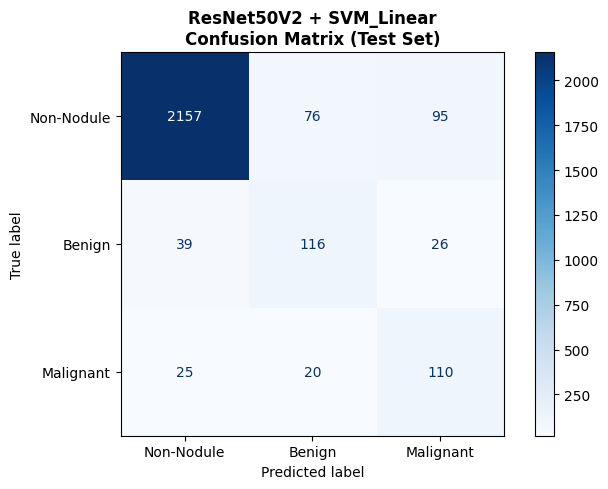

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.93      0.95      2328
            Benign       0.55      0.64      0.59       181
         Malignant       0.48      0.71      0.57       155
      
          accuracy                           0.89      2664
         macro avg       0.66      0.76      0.70      2664
      weighted avg       0.91      0.89      0.90      2664
      

   🔹 Classifier : XGBoost
      ⏳ Training on 41796 samples...
      Accuracy    : 90.69%
      F1 Macro    : 72.60%
      AUC (OvR)   : 0.9494
      Log Loss    : 0.3259
      Specificity : 91.19%
      ⏱️  Duration : 1744.8s (29.08 min)
      🌱 CO2eq    : 5.4734 g


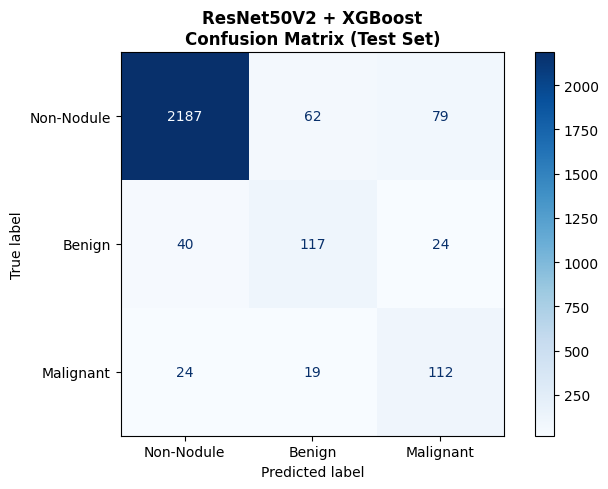

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.94      0.96      2328
            Benign       0.59      0.65      0.62       181
         Malignant       0.52      0.72      0.61       155
      
          accuracy                           0.91      2664
         macro avg       0.69      0.77      0.73      2664
      weighted avg       0.92      0.91      0.91      2664
      

   🔹 Classifier : RandomForest
      ⏳ Training on 41796 samples...
      Accuracy    : 90.43%
      F1 Macro    : 71.70%
      AUC (OvR)   : 0.9427
      Log Loss    : 0.4185
      Specificity : 90.67%
      ⏱️  Duration : 687.2s (11.45 min)
      🌱 CO2eq    : 2.1605 g


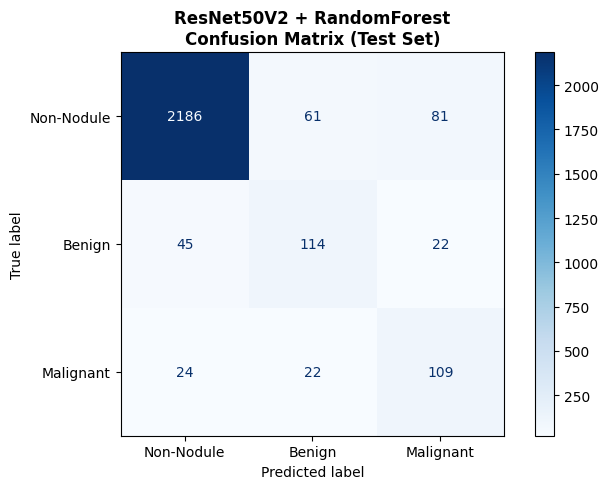

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.94      0.95      2328
            Benign       0.58      0.63      0.60       181
         Malignant       0.51      0.70      0.59       155
      
          accuracy                           0.90      2664
         macro avg       0.69      0.76      0.72      2664
      weighted avg       0.92      0.90      0.91      2664
      

🏗️  FEATURES : CBAM + DenseNet201
✅ DenseNet201 — Features loaded:
   Train+Val : (41796, 1920) | Test : (2664, 1920)

   🔹 Classifier : SVM_Linear
      ⏳ Training on 41796 samples...
      Accuracy    : 88.03%
      F1 Macro    : 67.82%
      AUC (OvR)   : 0.9146
      Log Loss    : 0.3466
      Specificity : 89.56%
      ⏱️  Duration : 333.1s (5.55 min)
      🌱 CO2eq    : 0.9358 g


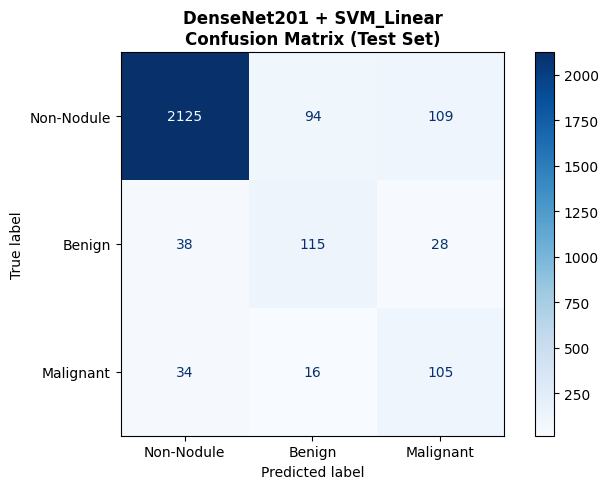

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.91      0.94      2328
            Benign       0.51      0.64      0.57       181
         Malignant       0.43      0.68      0.53       155
      
          accuracy                           0.88      2664
         macro avg       0.64      0.74      0.68      2664
      weighted avg       0.91      0.88      0.89      2664
      

   🔹 Classifier : XGBoost
      ⏳ Training on 41796 samples...
      Accuracy    : 89.64%
      F1 Macro    : 71.42%
      AUC (OvR)   : 0.9359
      Log Loss    : 0.3355
      Specificity : 90.82%
      ⏱️  Duration : 3138.3s (52.31 min)
      🌱 CO2eq    : 9.5810 g


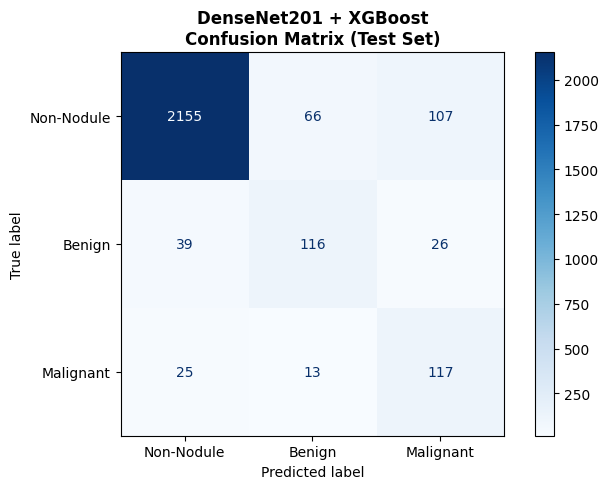

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.93      0.95      2328
            Benign       0.59      0.64      0.62       181
         Malignant       0.47      0.75      0.58       155
      
          accuracy                           0.90      2664
         macro avg       0.68      0.77      0.71      2664
      weighted avg       0.92      0.90      0.90      2664
      

   🔹 Classifier : RandomForest
      ⏳ Training on 41796 samples...
      Accuracy    : 89.11%
      F1 Macro    : 69.88%
      AUC (OvR)   : 0.9281
      Log Loss    : 0.3582
      Specificity : 90.64%
      ⏱️  Duration : 1925.1s (32.09 min)
      🌱 CO2eq    : 6.0545 g


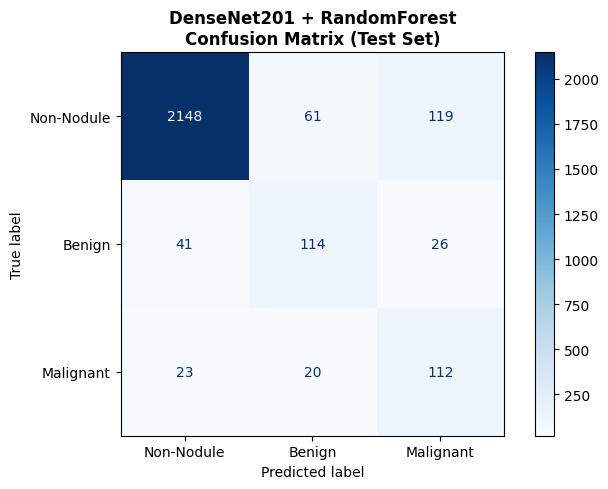

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.92      0.95      2328
            Benign       0.58      0.63      0.61       181
         Malignant       0.44      0.72      0.54       155
      
          accuracy                           0.89      2664
         macro avg       0.66      0.76      0.70      2664
      weighted avg       0.91      0.89      0.90      2664
      

🏗️  FEATURES : CBAM + EfficientNetB3
✅ EfficientNetB3 — Features loaded:
   Train+Val : (41796, 1536) | Test : (2664, 1536)

   🔹 Classifier : SVM_Linear
      ⏳ Training on 41796 samples...
      Accuracy    : 89.45%
      F1 Macro    : 71.36%
      AUC (OvR)   : 0.9378
      Log Loss    : 0.3122
      Specificity : 90.41%
      ⏱️  Duration : 559.0s (9.32 min)
      🌱 CO2eq    : 1.4878 g


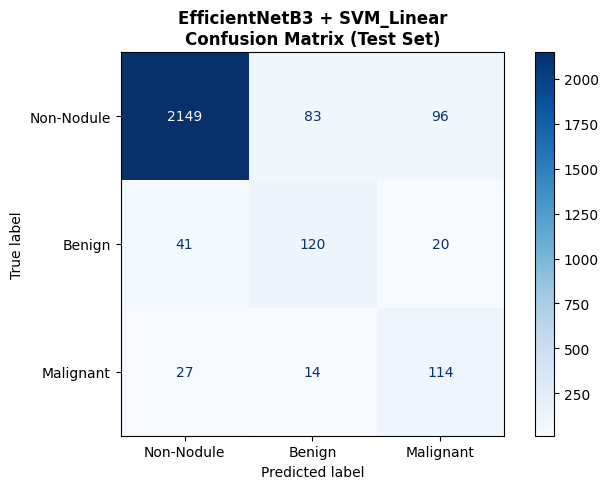

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.92      0.95      2328
            Benign       0.55      0.66      0.60       181
         Malignant       0.50      0.74      0.59       155
      
          accuracy                           0.89      2664
         macro avg       0.67      0.77      0.71      2664
      weighted avg       0.91      0.89      0.90      2664
      

   🔹 Classifier : XGBoost
      ⏳ Training on 41796 samples...
      Accuracy    : 91.14%
      F1 Macro    : 74.98%
      AUC (OvR)   : 0.9541
      Log Loss    : 0.3031
      Specificity : 91.27%
      ⏱️  Duration : 2084.3s (34.74 min)
      🌱 CO2eq    : 6.5029 g


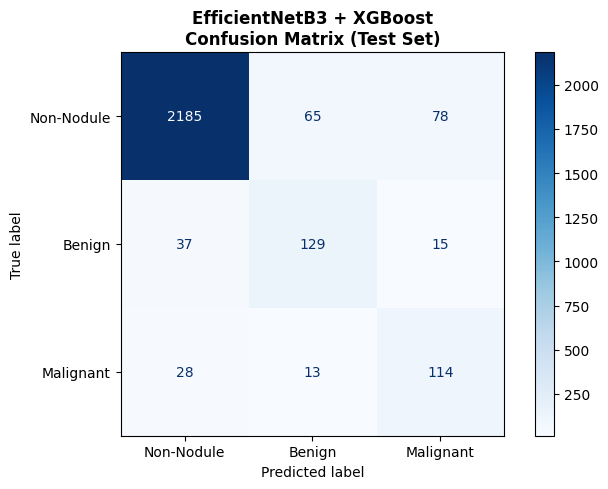

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.94      0.95      2328
            Benign       0.62      0.71      0.66       181
         Malignant       0.55      0.74      0.63       155
      
          accuracy                           0.91      2664
         macro avg       0.72      0.80      0.75      2664
      weighted avg       0.92      0.91      0.92      2664
      

   🔹 Classifier : RandomForest
      ⏳ Training on 41796 samples...
      Accuracy    : 90.58%
      F1 Macro    : 73.54%
      AUC (OvR)   : 0.9500
      Log Loss    : 0.2903
      Specificity : 91.41%
      ⏱️  Duration : 1866.5s (31.11 min)
      🌱 CO2eq    : 5.8736 g


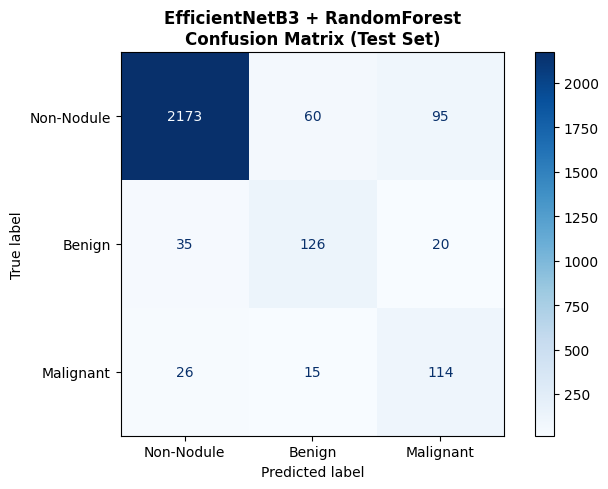

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.93      0.95      2328
            Benign       0.63      0.70      0.66       181
         Malignant       0.50      0.74      0.59       155
      
          accuracy                           0.91      2664
         macro avg       0.70      0.79      0.74      2664
      weighted avg       0.92      0.91      0.91      2664
      

🏗️  FEATURES : CBAM + EfficientNetV2L
✅ EfficientNetV2L — Features loaded:
   Train+Val : (41796, 1280) | Test : (2664, 1280)

   🔹 Classifier : SVM_Linear
      ⏳ Training on 41796 samples...
      Accuracy    : 90.92%
      F1 Macro    : 73.69%
      AUC (OvR)   : 0.9315
      Log Loss    : 0.3119
      Specificity : 92.39%
      ⏱️  Duration : 308.3s (5.14 min)
      🌱 CO2eq    : 0.8508 g


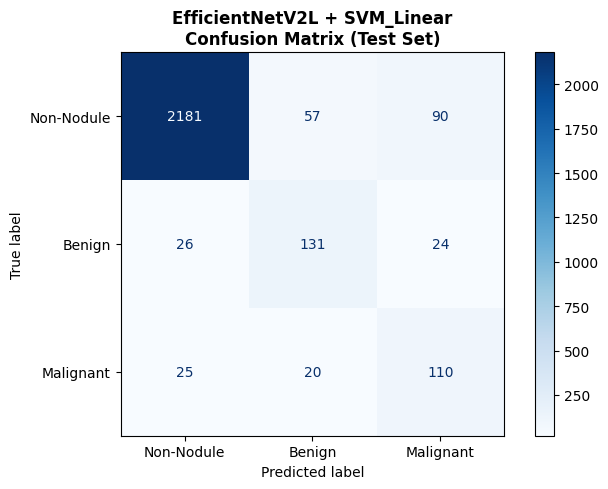

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.98      0.94      0.96      2328
            Benign       0.63      0.72      0.67       181
         Malignant       0.49      0.71      0.58       155
      
          accuracy                           0.91      2664
         macro avg       0.70      0.79      0.74      2664
      weighted avg       0.93      0.91      0.92      2664
      

   🔹 Classifier : XGBoost
      ⏳ Training on 41796 samples...
      Accuracy    : 90.65%
      F1 Macro    : 73.73%
      AUC (OvR)   : 0.9424
      Log Loss    : 0.3202
      Specificity : 92.30%
      ⏱️  Duration : 1347.8s (22.46 min)
      🌱 CO2eq    : 4.2276 g


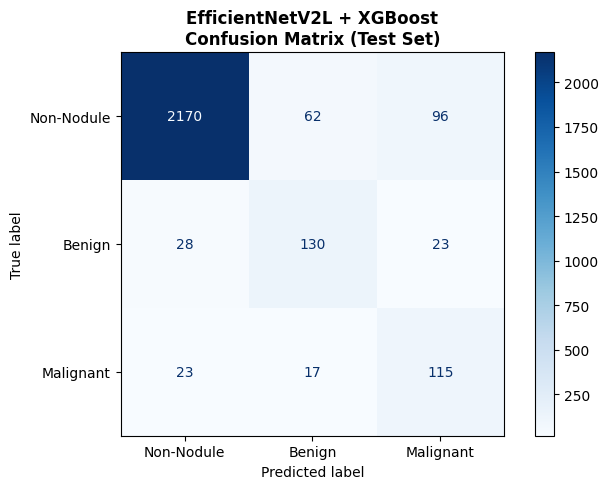

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.98      0.93      0.95      2328
            Benign       0.62      0.72      0.67       181
         Malignant       0.49      0.74      0.59       155
      
          accuracy                           0.91      2664
         macro avg       0.70      0.80      0.74      2664
      weighted avg       0.92      0.91      0.91      2664
      

   🔹 Classifier : RandomForest
      ⏳ Training on 41796 samples...
      Accuracy    : 90.17%
      F1 Macro    : 72.60%
      AUC (OvR)   : 0.9353
      Log Loss    : 0.4313
      Specificity : 91.70%
      ⏱️  Duration : 1834.6s (30.58 min)
      🌱 CO2eq    : 5.6765 g


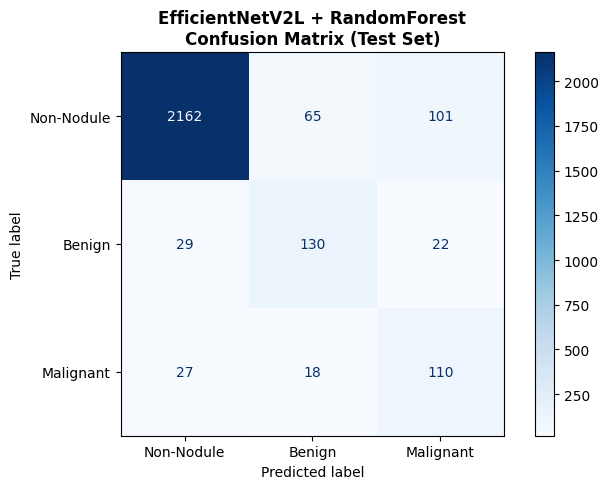

      📋 Classification Report:
                    precision    recall  f1-score   support
      
        Non-Nodule       0.97      0.93      0.95      2328
            Benign       0.61      0.72      0.66       181
         Malignant       0.47      0.71      0.57       155
      
          accuracy                           0.90      2664
         macro avg       0.69      0.79      0.73      2664
      weighted avg       0.92      0.90      0.91      2664
      

🏁 ALL EXPERIMENTS COMPLETED!
   Total combinations : 12


In [11]:
# =============================================
# CELL 6 : MAIN LOOP — 4 × 3 EXPERIMENTS
# =============================================
all_results  = []
carbon_log   = {}   # Carbon footprint per combination

for arch_name in ARCHITECTURES:
    print("\n" + "="*65)
    print(f"🏗️  FEATURES : CBAM + {arch_name}")
    print("="*65)

    # Load features
    feat = load_features(arch_name)
    if feat is None:
        print(f"⚠️  Skipping {arch_name} (missing features)")
        continue

    X_trainval, y_trainval, X_test, y_test, X_train, y_train, X_val, y_val = feat

    classifiers = get_classifiers()

    for clf_name, clf_pipeline in classifiers.items():
        combo_key = f"{arch_name}_{clf_name}"
        print(f"\n   🔹 Classifier : {clf_name}")

        # ─── Carbon tracker ───────────────────────────────────────────────────
        tracker = OfflineEmissionsTracker(
            project_name=f"ML_{combo_key}",
            output_dir=OUTPUT_DIR,
            output_file=f"{combo_key}_emissions.csv",
            country_iso_code="MAR",
            log_level="error"
        )
        tracker.start()
        t_start = time.time()

        # ─── Training ─────────────────────────────────────────────────────────
        print(f"      ⏳ Training on {X_trainval.shape[0]} samples...")
        clf_pipeline.fit(X_trainval, y_trainval)

        # ─── Prediction ───────────────────────────────────────────────────────
        y_pred  = clf_pipeline.predict(X_test)
        y_proba = clf_pipeline.predict_proba(X_test)

        t_end        = time.time()
        emissions_kg = tracker.stop()
        duration_s   = t_end - t_start
        duration_min = duration_s / 60

        # ─── Metrics ──────────────────────────────────────────────────────────
        metrics = compute_metrics(y_test, y_pred, y_proba, CLASS_NAMES)

        print(f"      Accuracy    : {metrics['accuracy']*100:.2f}%")
        print(f"      F1 Macro    : {metrics['f1_macro']*100:.2f}%")
        print(f"      AUC (OvR)   : {metrics['auc']:.4f}")
        print(f"      Log Loss    : {metrics['log_loss']:.4f}")
        print(f"      Specificity : {metrics['specificity_macro']*100:.2f}%")
        print(f"      ⏱️  Duration : {duration_s:.1f}s ({duration_min:.2f} min)")
        print(f"      🌱 CO2eq    : {float(emissions_kg)*1000:.4f} g")

        # ─── Save model ───────────────────────────────────────────────────────
        model_path = os.path.join(MODELS_DIR, f"{combo_key}.pkl")
        joblib.dump(clf_pipeline, model_path)

        # ─── Confusion Matrix ─────────────────────────────────────────────────
        fig, ax = plt.subplots(figsize=(7, 5))
        ConfusionMatrixDisplay(
            confusion_matrix=metrics['confusion_matrix'],
            display_labels=CLASS_NAMES
        ).plot(ax=ax, colorbar=True, cmap='Blues')
        ax.set_title(f'{arch_name} + {clf_name}\nConfusion Matrix (Test Set)', fontweight='bold')
        plt.tight_layout()
        cm_path = os.path.join(OUTPUT_DIR, f"{combo_key}_confusion_matrix.png")
        plt.savefig(cm_path, dpi=150, bbox_inches='tight')
        plt.show()

        print(f"      📋 Classification Report:")
        print("      " + classification_report(
            y_test, y_pred, target_names=CLASS_NAMES
        ).replace('\n', '\n      '))

        # ─── Store results ────────────────────────────────────────────────────
        carbon_log[combo_key] = {
            'duration_s'  : round(duration_s, 2),
            'duration_min': round(duration_min, 4),
            'co2_g'       : round(float(emissions_kg) * 1000, 6),
            'energy_kwh'  : round(float(emissions_kg) / 0.634, 6),
            'method'      : 'codecarbon_OfflineTracker_MAR'
        }

        all_results.append({
            'CNN_Architecture'      : arch_name,
            'ML_Classifier'         : clf_name,
            'Accuracy (%)'          : round(metrics['accuracy']*100, 2),
            'Precision_Macro (%)'   : round(metrics['precision_macro']*100, 2),
            'Recall_Macro (%)'      : round(metrics['recall_macro']*100, 2),
            'F1_Macro (%)'          : round(metrics['f1_macro']*100, 2),
            'F1_Weighted (%)'       : round(metrics['f1_weighted']*100, 2),
            'Log_Loss'              : round(metrics['log_loss'], 4),
            'AUC'                   : round(metrics['auc'], 4),
            'Specificity_Macro (%)' : round(metrics['specificity_macro']*100, 2),
            'Duration (s)'          : round(duration_s, 1),
            'Duration (min)'        : round(duration_min, 3),
            'CO2eq (g)'             : round(float(emissions_kg) * 1000, 6),
            'Energy (kWh)'          : round(float(emissions_kg) / 0.634, 6),
        })

# Save carbon log
with open(os.path.join(OUTPUT_DIR, 'ml_carbon_log.json'), 'w') as f:
    json.dump(carbon_log, f, indent=2)

print("\n🏁 ALL EXPERIMENTS COMPLETED!")
print(f"   Total combinations : {len(all_results)}")

In [13]:
# =============================================
# CELL 7 : COMPARATIVE TABLE
# =============================================
results_df = pd.DataFrame(all_results)

print("\n" + "="*120)
print("📊 FULL COMPARATIVE TABLE — 4 CNNs × 3 ML Classifiers (Test Set)")
print("="*120)
print(results_df.to_string(index=False))
print("="*120)

# Save CSV
csv_path = os.path.join(OUTPUT_DIR, 'comparative_results.csv')
results_df.to_csv(csv_path, index=False)

# Best combination
best_row = results_df.loc[results_df['Accuracy (%)'].idxmax()]
print(f"\n🏆 BEST COMBINATION:")
print(f"   CNN        : {best_row['CNN_Architecture']}")
print(f"   Classifier : {best_row['ML_Classifier']}")
print(f"   Accuracy   : {best_row['Accuracy (%)']}%")
print(f"   F1 Macro   : {best_row['F1_Macro (%)']}%")
print(f"   AUC        : {best_row['AUC']}")
print(f"   Log Loss   : {best_row['Log_Loss']}")
print(f"   CO2eq      : {best_row['CO2eq (g)']:.6f} g")
print(f"\n💾 Results saved: {csv_path}")


📊 FULL COMPARATIVE TABLE — 4 CNNs × 3 ML Classifiers (Test Set)
CNN_Architecture ML_Classifier  Accuracy (%)  Precision_Macro (%)  Recall_Macro (%)  F1_Macro (%)  F1_Weighted (%)  Log_Loss    AUC  Specificity_Macro (%)  Duration (s)  Duration (min)  CO2eq (g)  Energy (kWh)
      ResNet50V2    SVM_Linear         89.45                66.48             75.90         70.29            90.20    0.3118 0.9365                  90.75        5625.6          93.760  16.432457      0.025919
      ResNet50V2       XGBoost         90.69                69.45             76.95         72.60            91.19    0.3259 0.9494                  91.19        1744.8          29.081   5.473384      0.008633
      ResNet50V2  RandomForest         90.43                68.74             75.74         71.70            90.92    0.4185 0.9427                  90.67         687.2          11.453   2.160485      0.003408
     DenseNet201    SVM_Linear         88.03                63.74             74.19         67.

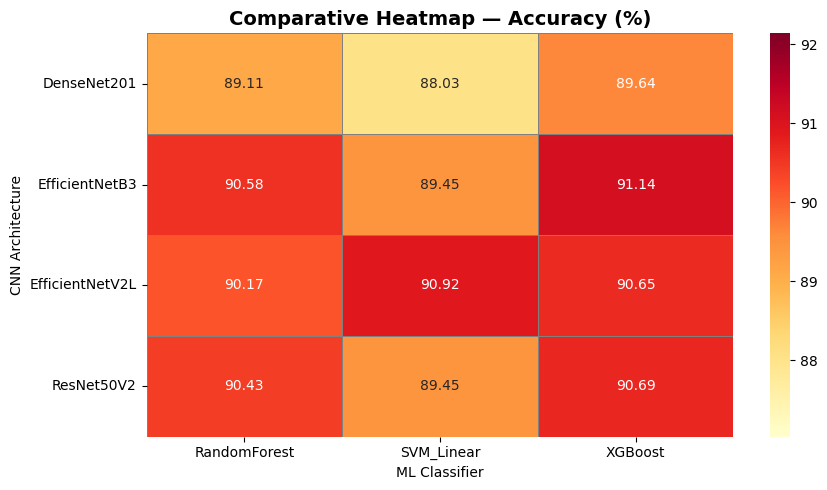

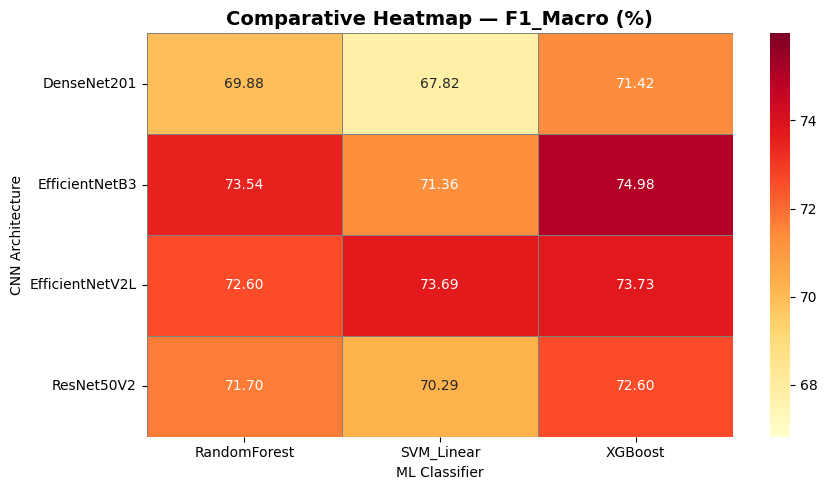

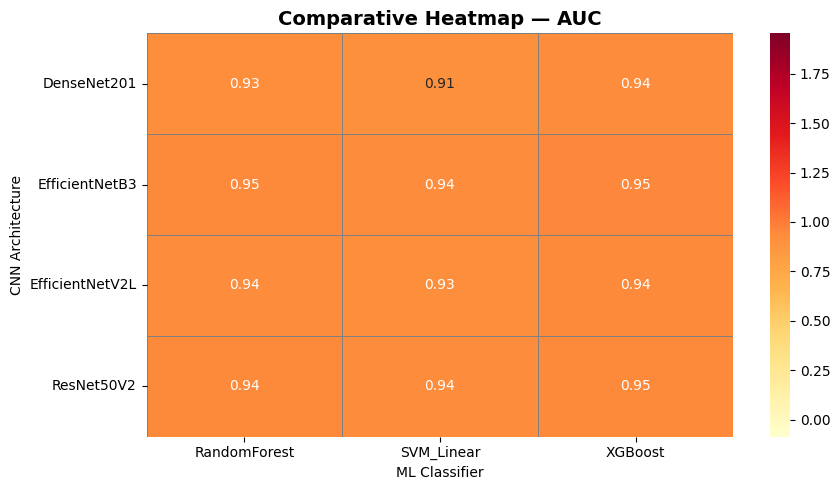

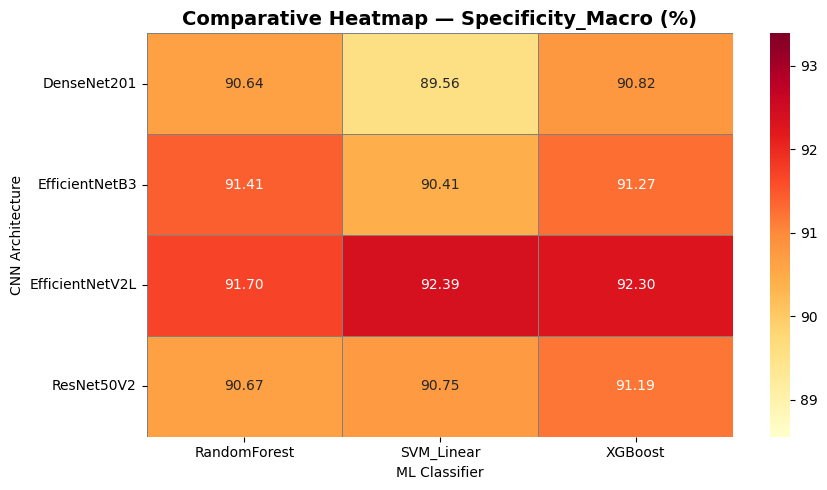

✅ Heatmaps saved.


In [14]:
# =============================================
# CELL 8 : HEATMAPS
# =============================================
for metric in ['Accuracy (%)', 'F1_Macro (%)', 'AUC', 'Specificity_Macro (%)']:
    pivot = results_df.pivot(
        index='CNN_Architecture', columns='ML_Classifier', values=metric
    )
    plt.figure(figsize=(9, 5))
    sns.heatmap(
        pivot, annot=True, fmt='.2f', cmap='YlOrRd',
        linewidths=0.5, linecolor='gray',
        vmin=pivot.values.min() - 1,
        vmax=pivot.values.max() + 1
    )
    plt.title(f'Comparative Heatmap — {metric}', fontsize=14, fontweight='bold')
    plt.ylabel('CNN Architecture')
    plt.xlabel('ML Classifier')
    plt.tight_layout()
    hm_path = os.path.join(OUTPUT_DIR, f'heatmap_{metric.split(" ")[0].lower()}.png')
    plt.savefig(hm_path, dpi=150, bbox_inches='tight')
    plt.show()

print("✅ Heatmaps saved.")

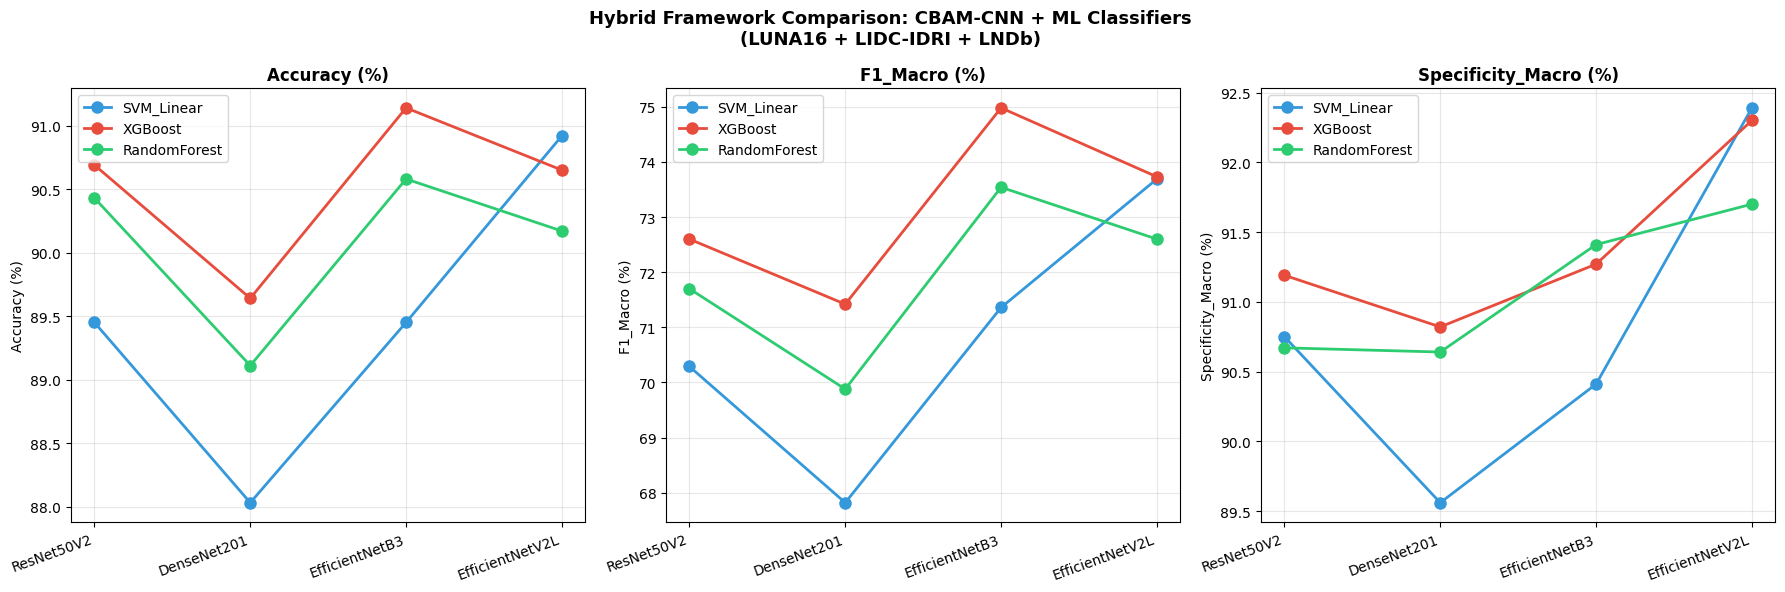

In [15]:
# =============================================
# CELL 9 : MULTI-METRIC LINE PLOT
# =============================================
metrics_to_plot = ['Accuracy (%)', 'F1_Macro (%)', 'Specificity_Macro (%)']
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(18, 6))

clf_colors = {
    'SVM_Linear'  : '#3498db',
    'XGBoost'     : '#e74c3c',
    'RandomForest': '#2ecc71'
}

for ax, metric in zip(axes, metrics_to_plot):
    for clf_name, color in clf_colors.items():
        subset = results_df[results_df['ML_Classifier'] == clf_name]
        ax.plot(subset['CNN_Architecture'], subset[metric],
                marker='o', linewidth=2, color=color,
                label=clf_name, markersize=8)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)
    ax.set_xticklabels(results_df['CNN_Architecture'].unique(), rotation=20, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Hybrid Framework Comparison: CBAM-CNN + ML Classifiers\n(LUNA16 + LIDC-IDRI + LNDb)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'multi_metric_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

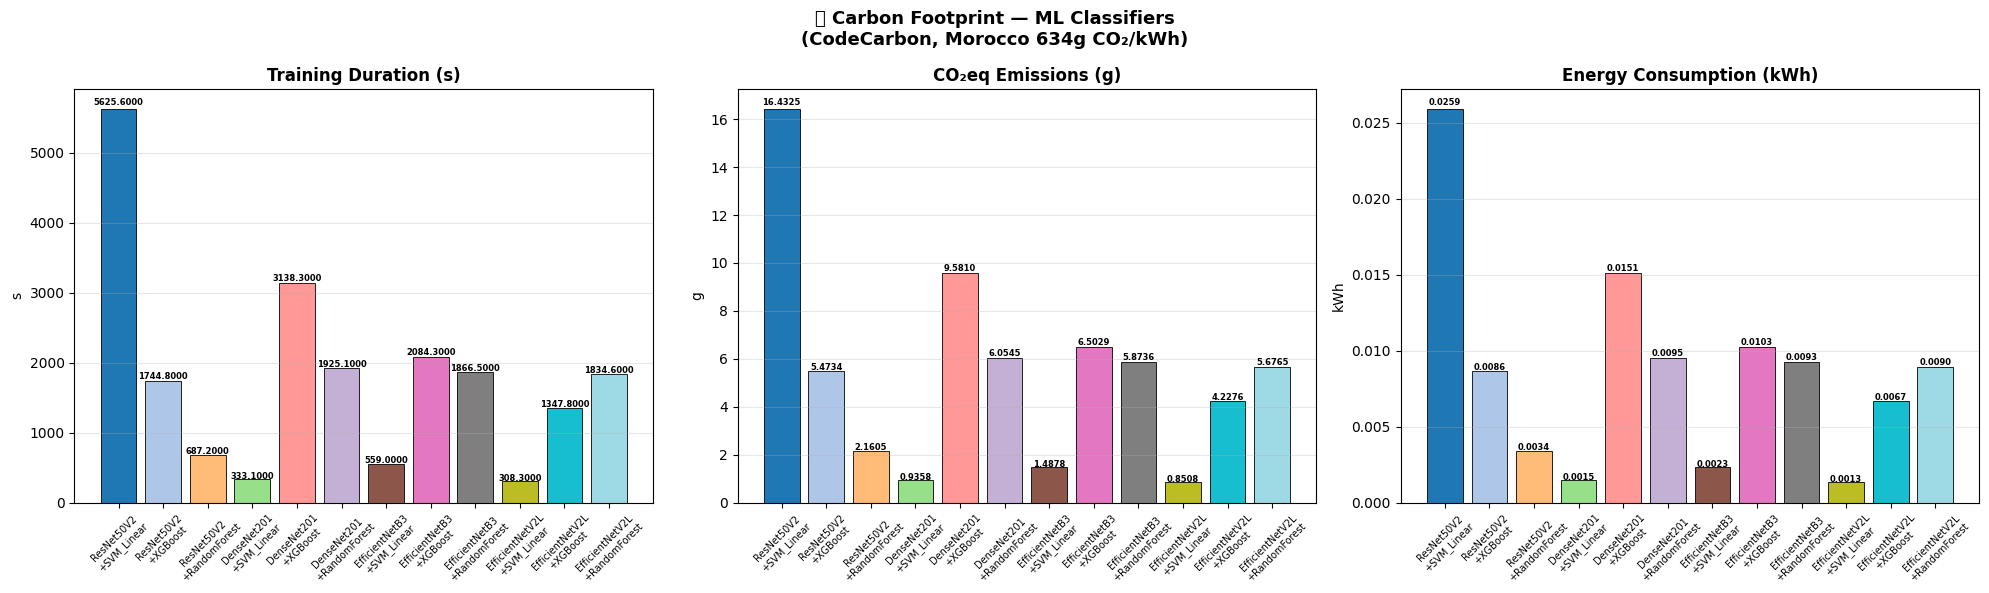


🌱 TOTAL CARBON FOOTPRINT — ML Training Phase:
   Total Duration : 21454.6s (357.6 min)
   Total CO2eq    : 65.256676 g
   Total Energy   : 0.102929 kWh
   Greenest combo : EfficientNetV2L +SVM_Linear
✅ Carbon summary saved.


In [16]:
# =============================================
# CELL 10 : CARBON FOOTPRINT VISUALIZATION
# =============================================
# Aggregate carbon per combination
carbon_df = results_df[[
    'CNN_Architecture', 'ML_Classifier', 'Duration (s)', 'CO2eq (g)', 'Energy (kWh)'
]].copy()
carbon_df['Combo'] = carbon_df['CNN_Architecture'] + '\n+' + carbon_df['ML_Classifier']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
colors_bar = plt.cm.tab20(np.linspace(0, 1, len(carbon_df)))

for ax, col, title, unit in [
    (axes[0], 'Duration (s)',  'Training Duration (s)',       's'),
    (axes[1], 'CO2eq (g)',     'CO₂eq Emissions (g)',         'g'),
    (axes[2], 'Energy (kWh)', 'Energy Consumption (kWh)',    'kWh'),
]:
    bars = ax.bar(carbon_df['Combo'], carbon_df[col],
                  color=colors_bar, edgecolor='black', linewidth=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(unit)
    ax.tick_params(axis='x', rotation=45, labelsize=7)
    ax.grid(True, alpha=0.3, axis='y')
    for bar, val in zip(bars, carbon_df[col]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
                f'{val:.4f}', ha='center', fontsize=6, fontweight='bold')

plt.suptitle('🌱 Carbon Footprint — ML Classifiers\n(CodeCarbon, Morocco 634g CO₂/kWh)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'ml_carbon_footprint.png'), dpi=150, bbox_inches='tight')
plt.show()

# Total carbon summary
print("\n🌱 TOTAL CARBON FOOTPRINT — ML Training Phase:")
print(f"   Total Duration : {carbon_df['Duration (s)'].sum():.1f}s ({carbon_df['Duration (s)'].sum()/60:.1f} min)")
print(f"   Total CO2eq    : {carbon_df['CO2eq (g)'].sum():.6f} g")
print(f"   Total Energy   : {carbon_df['Energy (kWh)'].sum():.6f} kWh")
print(f"   Greenest combo : {carbon_df.loc[carbon_df['CO2eq (g)'].idxmin(), 'Combo'].replace(chr(10), ' ')}")

# Save carbon summary CSV
carbon_df.to_csv(os.path.join(OUTPUT_DIR, 'ml_carbon_summary.csv'), index=False)
print("✅ Carbon summary saved.")

📊 Feature Importance Analysis (Random Forest):


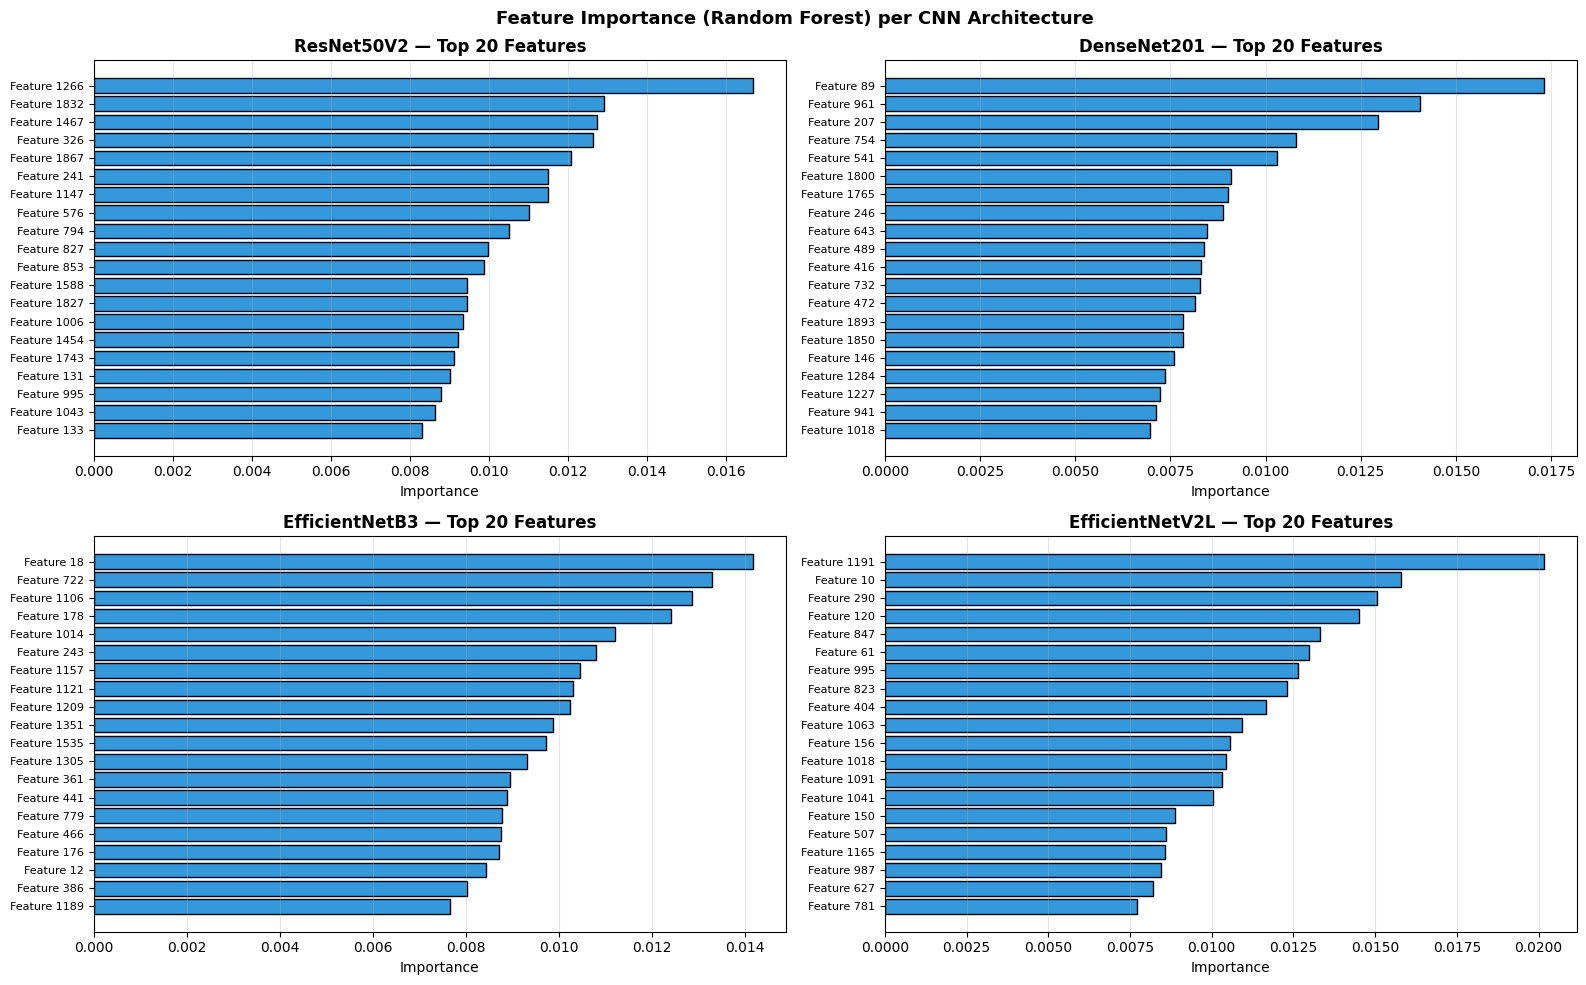

In [17]:
# =============================================
# CELL 11 : FEATURE IMPORTANCE (Random Forest)
# =============================================
print("📊 Feature Importance Analysis (Random Forest):")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, arch_name in enumerate(ARCHITECTURES):
    model_path = os.path.join(MODELS_DIR, f"{arch_name}_RandomForest.pkl")
    if not os.path.exists(model_path):
        print(f"   ⚠️  {arch_name}_RandomForest.pkl not found — skipping")
        continue

    pipeline    = joblib.load(model_path)
    rf_clf      = pipeline.named_steps['clf']
    importances = rf_clf.feature_importances_
    top_k       = 20
    top_idx     = np.argsort(importances)[::-1][:top_k]

    axes[i].barh(range(top_k), importances[top_idx][::-1],
                 color='#3498db', edgecolor='black')
    axes[i].set_yticks(range(top_k))
    axes[i].set_yticklabels([f'Feature {idx}' for idx in top_idx[::-1]], fontsize=8)
    axes[i].set_title(f'{arch_name} — Top {top_k} Features', fontweight='bold')
    axes[i].set_xlabel('Importance')
    axes[i].grid(True, alpha=0.3, axis='x')

plt.suptitle('Feature Importance (Random Forest) per CNN Architecture',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# =============================================
# CELL 13 : FINAL SUMMARY
# =============================================
print("\n" + "🏁 "*20)
print("NOTEBOOK 4 COMPLETE — Final Summary")
print("🏁 "*20)

best  = results_df.loc[results_df['Accuracy (%)'].idxmax()]
green = results_df.loc[results_df['CO2eq (g)'].idxmin()]

print(f"""
✅ Experiments completed:
   - {len(ARCHITECTURES)} CNN architectures + CBAM
   - 3 ML classifiers (Linear SVM, XGBoost, Random Forest)
   - {len(all_results)} combinations evaluated
   - Metrics: Accuracy, Precision, Recall, F1, Log Loss, AUC, Specificity
   - Execution time + Carbon footprint (CodeCarbon, Morocco)

🏆 BEST ACCURACY : {best['CNN_Architecture']} + {best['ML_Classifier']}
   Accuracy : {best['Accuracy (%)']}% | F1 : {best['F1_Macro (%)']}% | AUC : {best['AUC']}

🌱 GREENEST COMBO : {green['CNN_Architecture']} + {green['ML_Classifier']}
   CO2eq : {green['CO2eq (g)']:.6f} g | Duration : {green['Duration (s)']:.1f}s

📁 Files generated in {OUTPUT_DIR}:
   - comparative_results.csv      ← Full comparative table
   - table_ml_results.tex         ← LaTeX table for publication
   - heatmap_*.png                ← Heatmaps (Accuracy, F1, AUC, Specificity)
   - multi_metric_comparison.png  ← Multi-metric line plot
   - ml_carbon_footprint.png      ← Carbon footprint visualization
   - ml_carbon_summary.csv        ← Carbon data per combination
   - ml_carbon_log.json           ← Detailed carbon log
   - feature_importance.png       ← Random Forest feature importance
   - *_confusion_matrix.png       ← Confusion matrices (12 combinations)

🔬 Article: A Comparative Hybrid Framework for Lung Nodule Classification:
            Integrating CBAM-Enhanced CNNs with Traditional ML on Multi-Source CT Datasets
""")


🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 
NOTEBOOK 4 COMPLETE — Final Summary
🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 🏁 

✅ Experiments completed:
   - 4 CNN architectures + CBAM
   - 3 ML classifiers (Linear SVM, XGBoost, Random Forest)
   - 12 combinations evaluated
   - Metrics: Accuracy, Precision, Recall, F1, Log Loss, AUC, Specificity
   - Execution time + Carbon footprint (CodeCarbon, Morocco)

🏆 BEST ACCURACY : EfficientNetB3 + XGBoost
   Accuracy : 91.14% | F1 : 74.98% | AUC : 0.9541

🌱 GREENEST COMBO : EfficientNetV2L + SVM_Linear
   CO2eq : 0.850774 g | Duration : 308.3s

📁 Files generated in /content/drive/MyDrive/Journal_Work_2026/ML_Results:
   - comparative_results.csv      ← Full comparative table
   - table_ml_results.tex         ← LaTeX table for publication
   - heatmap_*.png                ← Heatmaps (Accuracy, F1, AUC, Specificity)
   - multi_metric_comparison.png  ← Multi-metric line plot
   - ml_carbon_footprint.png      ← Carbon footprint visualization
   - ml_car